# RNN-Based Text Classification Using AG News Dataset
### Building and Comparing RNN, LSTM, GRU, and Bi-LSTM Models for News Topic Classification

This notebook classifies news articles from the **AG News** dataset into four categories (World, Sports, Business, Sci/Tech). It builds and compares four sequence models (Simple RNN, LSTM, GRU and Bi-LSTM) and studies the effect of gradient clipping.

---

## Task 1: Load and Explore the Dataset

In this task, the AG News dataset is loaded using the Hugging Face `datasets` library and explored by examining its structure, size, sample articles and class distribution.

In [1]:
# Install the Hugging Face datasets library
!pip install datasets

# Confirm TensorFlow works and the GPU is visible
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPUs available    :", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPUs available    : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset

# Load the AG News dataset
dataset = load_dataset("fancyzhx/ag_news")

class_names = dataset["train"].features["label"].names
print("Class names:", class_names)

README.md:   0%|          | 0.00/8.07k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 18.6MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 1.23MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/120000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/7600 [00:00<?, ? examples/s]

Class names: ['World', 'Sports', 'Business', 'Sci/Tech']


### 1. Display the Dataset Structure

The dataset is organized as a `DatasetDict` containing a training split and a test split. Each record has two fields: `text` (the news article) and `label` (the category as an integer).

In [9]:
# Overall structure: splits, columns and number of rows
print("Dataset structure:")
print(dataset)

# Feature types for each column
print("\nFeatures:")
print(dataset["train"].features)

Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['text', 'label'],
        num_rows: 120000
    })
    test: Dataset({
        features: ['text', 'label'],
        num_rows: 7600
    })
})

Features:
{'text': Value('string'), 'label': ClassLabel(names=['World', 'Sports', 'Business', 'Sci/Tech'])}


### 2. Number of Training and Test Samples

In [11]:
# Number of samples in each split
num_train = len(dataset["train"])
num_test = len(dataset["test"])

print("Number of training samples:", num_train)
print("Number of test samples    :", num_test)
print("Total samples             :", num_train + num_test)

Number of training samples: 120000
Number of test samples    : 7600
Total samples             : 127600


### 3. Display 5 Sample News Articles with Their Labels

Five articles are picked at random from the training set (with a fixed seed so the selection is reproducible). Each label is shown as both its integer value and its category name.

In [12]:
# Pick 5 random training articles (fixed seed for reproducibility)
rng = np.random.default_rng(42)
sample_indices = rng.choice(num_train, size=5, replace=False)

for i, idx in enumerate(sample_indices, start=1):
    record = dataset["train"][int(idx)]
    label_id = record["label"]
    print(f"Sample {i}")
    print(f"Label : {label_id} ({class_names[label_id]})")
    print(f"Text  : {record['text']}")
    print("-" * 80)

Sample 1
Label : 2 (Business)
Text  : S P Lowers Merck Debt Rating Amid Vioxx Concern A third major debt ratings agency has stripped Merck  #38; Co. of its top credit grade, lowering the drug maker's classification by three notches amid concerns stemming from its recall of the arthritis drug Vioxx.
--------------------------------------------------------------------------------
Sample 2
Label : 2 (Business)
Text  : Australian PM gets election boost with surprise drop in &lt;b&gt;...&lt;/b&gt; SYDNEY : Prime Minister John Howard #39;s election campaign received a last-minute boost as new unemployment figures showed a larger than expected fall in the number of jobless, two days before an election he has fought on his economic record.
--------------------------------------------------------------------------------
Sample 3
Label : 0 (World)
Text  : Video shows UN hostages in Afghanistan Arabic TV network Al-Jazeera Sunday aired video showing three UN election workers taken hostage in Afgh

### 4. Check the Distribution of All 4 Classes

The number of articles in each category is counted for both the training and test sets, with percentages, to check whether the classes are balanced.

In [13]:
# Convert the splits to pandas DataFrames for easy counting
train_df = dataset["train"].to_pandas()
test_df = dataset["test"].to_pandas()

# Count samples per class
train_counts = train_df["label"].value_counts().sort_index()
test_counts = test_df["label"].value_counts().sort_index()

# Build a class distribution table
distribution_table = pd.DataFrame({
    "Label": train_counts.index,
    "Category": [class_names[i] for i in train_counts.index],
    "Train Count": train_counts.values,
    "Train %": (train_counts.values / num_train * 100).round(2),
    "Test Count": test_counts.values,
    "Test %": (test_counts.values / num_test * 100).round(2),
})

print("Class distribution table:")
display(distribution_table)

Class distribution table:


,Label,Category,Train Count,Train %,Test Count,Test %
0,0,World,30000,25.0,1900,25.0
1,1,Sports,30000,25.0,1900,25.0
2,2,Business,30000,25.0,1900,25.0
3,3,Sci/Tech,30000,25.0,1900,25.0


### 5. Plot the Class Distribution

Bar charts show the number of samples in each category for the training and test sets.

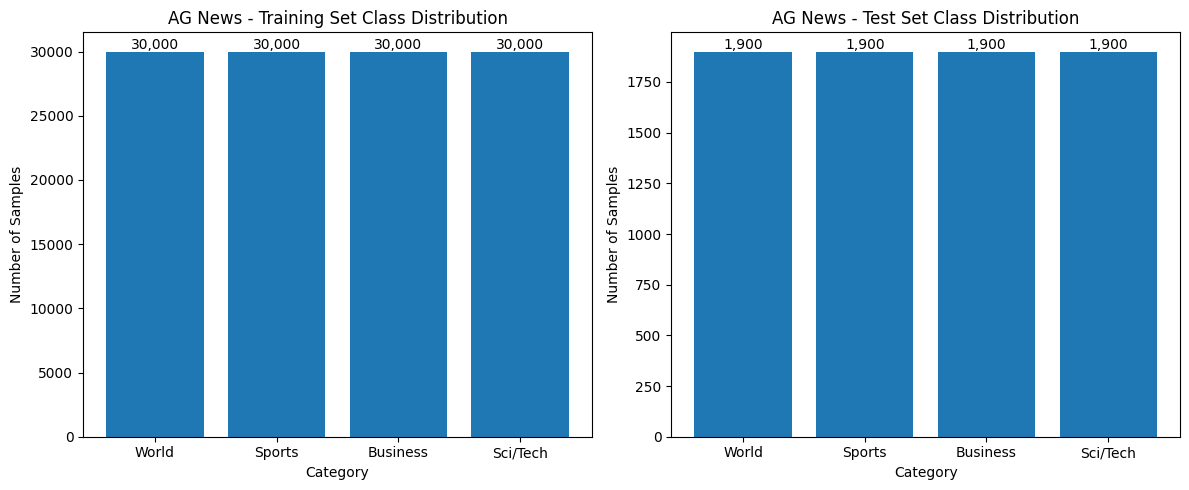

In [14]:
# Plot class distribution for training and test sets side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Training set
axes[0].bar(class_names, train_counts.values)
axes[0].set_title("AG News - Training Set Class Distribution")
axes[0].set_xlabel("Category")
axes[0].set_ylabel("Number of Samples")
for i, count in enumerate(train_counts.values):
    axes[0].text(i, count, f"{count:,}", ha="center", va="bottom")

# Test set
axes[1].bar(class_names, test_counts.values)
axes[1].set_title("AG News - Test Set Class Distribution")
axes[1].set_xlabel("Category")
axes[1].set_ylabel("Number of Samples")
for i, count in enumerate(test_counts.values):
    axes[1].text(i, count, f"{count:,}", ha="center", va="bottom")

plt.tight_layout()
plt.show()

### Observations: Task 1

- **Dataset structure:** AG News is a `DatasetDict` with a `train` split and a `test` split. Each record has two fields: `text` (a string) and `label` (a `ClassLabel` with 4 categories: World, Sports, Business, Sci/Tech).
- **Size:** The training set contains **120,000** articles and the test set contains **7,600** articles, 127,600 in total. The dataset is large enough to train sequence models from scratch.
- **Class balance:** The dataset is **perfectly balanced**. Every class has 30,000 training samples and 1,900 test samples, which is exactly 25% of each split. No class is over- or under-represented.
- **Implication for evaluation:** Because the classes are balanced, a model guessing at random would score about 25%, and **accuracy is a fair and sufficient metric** for comparing models. Techniques for handling class imbalance, such as class weights or macro F1, are not needed here.
- **Nature of the text:** Each sample combines a short headline with a one- or two-sentence description, so the articles are short. The sample articles are clearly distinguishable by topic (for example, debt ratings and unemployment figures for Business, hostages and elections for World, and a mobile phone system for Sci/Tech).
- **Data quality note:** Some samples contain leftover HTML and encoding artifacts, such as `#39;` (an apostrophe), `#38;` (an ampersand) and `&lt;b&gt;...&lt;/b&gt;`. These will be tokenized like ordinary words, so they are worth keeping in mind during text preprocessing in Task 2.

## Task 2: Text Preprocessing

Neural networks cannot work with raw text, so the news articles must be converted into fixed-size numerical arrays. This task follows the standard NLP preprocessing pipeline:

1. Extract the text and label columns
2. Tokenize the text and build a vocabulary limited to 20,000 words
3. Convert the text into integer sequences
4. Pad (or truncate) all sequences to a fixed length
5. Prepare the labels for multi-class classification

**Shared settings:** the same vocabulary size, sequence length, padding strategy and label format are used for all four models (Simple RNN, LSTM, GRU and Bi-LSTM) so that the comparison is fair.

In [16]:
import re
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Shared settings used for ALL models
VOCAB_SIZE = 20000      # maximum vocabulary size (as required)
MAX_LEN = 100           # fixed sequence length
OOV_TOKEN = "<OOV>"     # placeholder for words outside the vocabulary

### 1. Extract the Text and Label Columns

The `text` and `label` columns are extracted from the training and test splits created in Task 1.

In [17]:
# Extract text and labels from both splits
train_texts_raw = train_df["text"].tolist()
test_texts_raw = test_df["text"].tolist()

y_train = train_df["label"].values
y_test = test_df["label"].values

print("Training texts :", len(train_texts_raw))
print("Test texts     :", len(test_texts_raw))
print("Training labels:", len(y_train))
print("Test labels    :", len(y_test))

Training texts : 120000
Test texts     : 7600
Training labels: 120000
Test labels    : 7600


#### Light Cleaning of HTML Artifacts

In Task 1, some articles were seen to contain leftover HTML codes (for example `#39;` for an apostrophe, `#38;` for an ampersand and `&lt;b&gt;...&lt;/b&gt;` tags). A small cleaning function replaces these with their proper characters or removes them. The same function is applied to both the training and test text. No other cleaning is done, because the tokenizer already handles lowercasing and punctuation.

In [18]:
def clean_text(text):
    """Fix common HTML artifacts found in AG News."""
    text = re.sub(r"&lt;.*?&gt;", " ", text)    # encoded HTML tags, e.g. &lt;b&gt;...&lt;/b&gt;
    text = re.sub(r"\s*#39;", "'", text)        # encoded apostrophe
    text = re.sub(r"\s*#38;", " and ", text)    # encoded ampersand
    text = re.sub(r"#\d+;", " ", text)          # any other leftover numeric HTML codes
    text = re.sub(r"\s+", " ", text).strip()    # tidy up extra spaces
    return text

# Show one before/after example
example = next(t for t in train_texts_raw if "#39;" in t)
print("BEFORE:", example)
print("AFTER :", clean_text(example))

# Apply cleaning to both splits
train_texts = [clean_text(t) for t in train_texts_raw]
test_texts = [clean_text(t) for t in test_texts_raw]

BEFORE: Last Call for Investors to Bid on Google NEW YORK (Reuters) - Time is running out for prospective investors to submit their offers to buy shares of Google Inc, the Web #39;s No. 1 search company. 
AFTER : Last Call for Investors to Bid on Google NEW YORK (Reuters) - Time is running out for prospective investors to submit their offers to buy shares of Google Inc, the Web's No. 1 search company.


### 2 & 3. Tokenize the Text and Limit the Vocabulary to 20,000 Words

The Keras `Tokenizer` splits text into words, converts them to lowercase, removes punctuation and builds a word-to-integer dictionary ordered by word frequency. Key points:

- `num_words=20000` keeps only the most frequent words.
- `oov_token` gives every out-of-vocabulary (rare) word a shared placeholder ID instead of silently dropping it.
- The tokenizer is **fitted on the training text only**, so no information from the test set leaks into the vocabulary.

In [20]:
# Build the vocabulary from the training text only
tokenizer = Tokenizer(num_words=VOCAB_SIZE, oov_token=OOV_TOKEN)
tokenizer.fit_on_texts(train_texts)

print("Unique words found in training text:", len(tokenizer.word_index))
print("Vocabulary size kept by the model  :", VOCAB_SIZE)

# Ten most frequent words and their IDs (ID 1 is the OOV placeholder)
print("\nTop 10 entries in the word index:")
print(list(tokenizer.word_index.items())[:10])

Unique words found in training text: 75344
Vocabulary size kept by the model  : 20000

Top 10 entries in the word index:
[('<OOV>', 1), ('the', 2), ('to', 3), ('a', 4), ('of', 5), ('in', 6), ('and', 7), ('on', 8), ('for', 9), ('that', 10)]


### 4. Convert Text into Numerical Sequences

Each article is converted into a list of integers by replacing every word with its ID from the vocabulary. Before choosing the fixed sequence length, the distribution of article lengths is examined.

Text     : Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.
Sequence : [423, 420, 1759, 14611, 100, 59, 2, 843, 22, 22, 728, 8208, 423, 3941, 10237, 3028, 5, 5794, 1, 37, 4030, 785, 313]

Article length statistics (words):
Mean   : 38.1
Median : 38
95th percentile: 53
99th percentile: 71
Maximum: 177
Articles with length <= 100: 99.82%
Articles with length <= 150: 99.99%


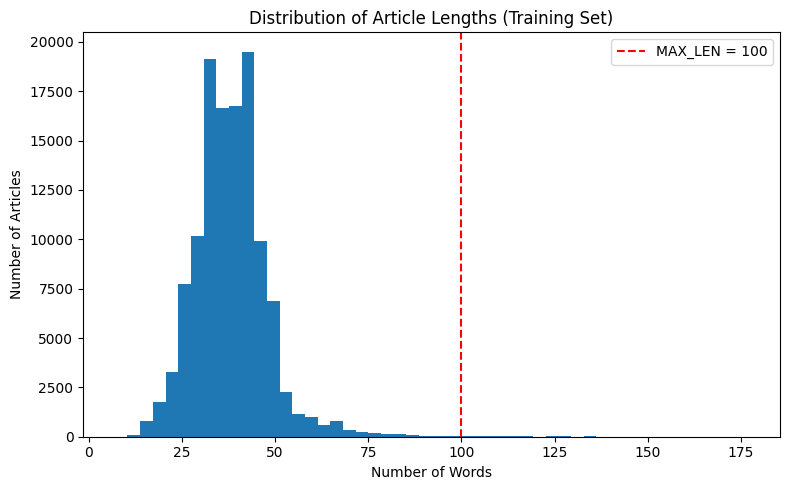

In [21]:
# Convert text to integer sequences
train_sequences = tokenizer.texts_to_sequences(train_texts)
test_sequences = tokenizer.texts_to_sequences(test_texts)
# using the same vocabulary for the test data. So the same tokenizer being used.

# Example: first training article
print("Text     :", train_texts[0])
print("Sequence :", train_sequences[0])

# Length analysis (number of words per article, before padding)
train_lengths = np.array([len(seq) for seq in train_sequences])

print("\nArticle length statistics (words):")
print("Mean   :", round(train_lengths.mean(), 1))
print("Median :", int(np.median(train_lengths)))
print("95th percentile:", int(np.percentile(train_lengths, 95)))
print("99th percentile:", int(np.percentile(train_lengths, 99)))
print("Maximum:", train_lengths.max())

for length in (100, 150):
    covered = (train_lengths <= length).mean() * 100
    print(f"Articles with length <= {length}: {covered:.2f}%")

# Histogram of article lengths
plt.figure(figsize=(8, 5))
plt.hist(train_lengths, bins=50)
plt.axvline(MAX_LEN, color="red", linestyle="--", label=f"MAX_LEN = {MAX_LEN}")
plt.title("Distribution of Article Lengths (Training Set)")
plt.xlabel("Number of Words")
plt.ylabel("Number of Articles")
plt.legend()
plt.tight_layout()
plt.show()

### 5 & 6. Apply Padding with a Fixed Maximum Sequence Length

All sequences must have the same length so they can be stacked into one array for training. Using `MAX_LEN = 100`:

- **Short articles** are padded with zeros at the **start** (`padding="pre"`). This is preferred for RNNs, because the network reads left to right and the real words then come last, just before the final hidden state is used for classification.
- **Long articles** are truncated at the **end** (`truncating="post"`), so the headline and opening words, which usually carry the topic, are kept.

In [22]:
# Pad / truncate all sequences to MAX_LEN
X_train = pad_sequences(train_sequences, maxlen=MAX_LEN, padding="pre", truncating="post")
X_test = pad_sequences(test_sequences, maxlen=MAX_LEN, padding="pre", truncating="post")

# Example: first article before and after padding
print("Before padding (length", len(train_sequences[0]), "):", train_sequences[0])
print("After padding  (length", len(X_train[0]), "):", X_train[0])

Before padding (length 23 ): [423, 420, 1759, 14611, 100, 59, 2, 843, 22, 22, 728, 8208, 423, 3941, 10237, 3028, 5, 5794, 1, 37, 4030, 785, 313]
After padding  (length 100 ): [    0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0     0     0     0     0     0     0     0
     0     0     0     0     0   423   420  1759 14611   100    59     2
   843    22    22   728  8208   423  3941 10237  3028     5  5794     1
    37  4030   785   313]


### 7. Prepare the Labels for Multi-Class Classification

The labels are already integers from 0 to 3 (World, Sports, Business, Sci/Tech), so they are kept in **integer format**. They are used with the `sparse_categorical_crossentropy` loss, which converts them to one-hot form internally. The output layer of every model has 4 neurons with softmax activation.

In [23]:
# Labels stay as integers (0-3) for sparse_categorical_crossentropy
y_train = y_train.astype("int64")
y_test = y_test.astype("int64")

print("First 10 training labels:", y_train[:10])
print("Unique labels:", np.unique(y_train))
print("Label meaning:", dict(enumerate(class_names)))

First 10 training labels: [2 2 2 2 2 2 2 2 2 2]
Unique labels: [0 1 2 3]
Label meaning: {0: 'World', 1: 'Sports', 2: 'Business', 3: 'Sci/Tech'}


### Processed Data Shapes

In [24]:
# Final shapes of the processed data
print("Processed training data shape:", X_train.shape)
print("Processed test data shape    :", X_test.shape)
print("Training labels shape        :", y_train.shape)
print("Test labels shape            :", y_test.shape)

# Decode one padded sequence back to words to verify the pipeline
index_to_word = {idx: word for word, idx in tokenizer.word_index.items()}
decoded = " ".join(index_to_word.get(i, "") for i in X_train[0] if i != 0)
print("\nDecoded first article:", decoded)
print("Original (cleaned)   :", train_texts[0])

Processed training data shape: (120000, 100)
Processed test data shape    : (7600, 100)
Training labels shape        : (120000,)
Test labels shape            : (7600,)

Decoded first article: wall st bears claw back into the black reuters reuters short sellers wall street's dwindling band of ultra <OOV> are seeing green again
Original (cleaned)   : Wall St. Bears Claw Back Into the Black (Reuters) Reuters - Short-sellers, Wall Street's dwindling\band of ultra-cynics, are seeing green again.


### Why Are Tokenization and Padding Needed?

**Tokenization** is needed because neural networks can only perform mathematical operations on numbers, not on raw text. The tokenizer splits each article into words and maps every word to an integer ID, producing a sequence that keeps the original word order, which is essential for RNN-based models. Limiting the vocabulary to the 20,000 most frequent words keeps the Embedding layer manageable and prevents the model from wasting capacity on rare words and typos, while the OOV token still marks where an unknown word occurred.

**Padding** is needed because articles have different lengths, but neural networks are trained on batches that must form a rectangular array with the same number of columns in every row. Padding short sequences with zeros and truncating long ones to a fixed length (`MAX_LEN = 100`) makes every article the same size. The choice of length balances information loss against wasted computation on padding.

### Observations: Task 2

- **Cleaning:** Some articles contained leftover HTML codes (`#39;`, `#38;`, `&lt;b&gt;`). A small cleaning function, applied identically to the training and test text, replaced them with proper characters (for example `Web #39;s` became `Web's`).
- **Vocabulary:** The training text contains **75,344 unique words**. Only the **20,000 most frequent** are kept; every other word maps to a shared `<OOV>` token (for example, the rare word "cynics" in the first article). The most frequent words are common function words such as "the", "to", "a" and "of".
- **Article length:** Articles are short, with a mean of 38.1 words, a median of 38, a 95th percentile of 53, a 99th percentile of 71 and a maximum of 177 words.
- **Choice of sequence length:** `MAX_LEN = 100` keeps **99.82%** of articles completely intact, while `MAX_LEN = 150` would cover only 0.17% more (99.99%) at the cost of more padding and slower RNN training. A length of 100 was therefore used for all models.
- **Padding strategy:** Short articles are padded with zeros at the **start** (pre-padding) so the real words come last, just before the RNN's final hidden state is used for classification. Long articles are truncated at the end, preserving the headline and opening words. Since the average article has about 38 words, roughly 62% of each padded sequence is padding.
- **Final shapes:** Training data `(120000, 100)`, test data `(7600, 100)`, training labels `(120000,)` and test labels `(7600,)`.
- **Labels:** The labels are kept as integers 0 to 3 and will be used with `sparse_categorical_crossentropy`. Each model will end in a 4-neuron softmax layer.


## Task 3: Build a Simple RNN Model

A Simple RNN reads each article one word at a time, carrying a hidden state (a running memory) from one step to the next. The final hidden state summarizes the whole article and is passed to the classification layers.

### Shared Experimental Setup

To keep the comparison between all four models (Simple RNN, LSTM, GRU and Bi-LSTM) fair, the following settings are defined once and reused for every model:

| Setting | Value |
|---|---|
| Vocabulary size | 20,000 |
| Sequence length | 100 |
| Embedding dimension | 64 |
| Recurrent layer units | 64 |
| Dense hidden layer | 64 units, ReLU |
| Output layer | 4 units, softmax |
| Optimizer | Adam (default learning rate) |
| Loss | sparse categorical cross-entropy |
| Epochs | 10 |
| Batch size | 128 |
| Training / validation / test data | 96,000 / 24,000 / 7,600 articles |

The only thing that changes from one model to the next is the recurrent layer itself. The random seed is also reset before each model is built, so weight initialization is consistent. Padding zeros are not masked, again to keep all models identical.

In [25]:
from sklearn.model_selection import train_test_split

# Stratified random split: same class proportions in training and validation
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train, y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("Training set shape  :", X_tr.shape, y_tr.shape)
print("Validation set shape:", X_val.shape, y_val.shape)
print("Test set shape      :", X_test.shape, y_test.shape)

print("\nClass counts in training set  :", np.bincount(y_tr))
print("Class counts in validation set:", np.bincount(y_val))

Training set shape  : (96000, 100) (96000,)
Validation set shape: (24000, 100) (24000,)
Test set shape      : (7600, 100) (7600,)

Class counts in training set  : [24000 24000 24000 24000]
Class counts in validation set: [6000 6000 6000 6000]


In [26]:
import time
from tensorflow.keras import Sequential, Input
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

# ---------------- Shared settings (used for ALL models) ----------------
EMBED_DIM = 64        # size of each word vector
HIDDEN_UNITS = 64     # units in the recurrent layer
DENSE_UNITS = 64      # units in the Dense hidden layer
NUM_CLASSES = 4       # World, Sports, Business, Sci/Tech
EPOCHS = 10
BATCH_SIZE = 128
SEED = 42

# Dictionary that will collect the results of every model (used in Task 8)
results = {}


def build_model(rnn_layer, optimizer="adam"):
    """Embedding -> recurrent layer -> Dense hidden -> softmax output."""
    tf.keras.utils.set_random_seed(SEED)   # same weight initialization setup for every model
    model = Sequential([
        Input(shape=(MAX_LEN,)),
        Embedding(input_dim=VOCAB_SIZE, output_dim=EMBED_DIM),
        rnn_layer,
        Dense(DENSE_UNITS, activation="relu"),
        Dense(NUM_CLASSES, activation="softmax"),
    ])
    model.compile(
        loss="sparse_categorical_crossentropy",
        optimizer=optimizer,
        metrics=["accuracy"],
    )
    return model


def train_model(model, name):
    """Train the model and measure the training time."""
    start = time.time()
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1,
    )
    train_time = time.time() - start
    print(f"\n{name} training time: {train_time:.1f} seconds ({train_time / 60:.1f} minutes)")
    return history, train_time


def evaluate_model(model, history, train_time, name):
    """Evaluate on the test set and store all results for the final comparison."""
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    results[name] = {
        "train_acc": history.history["accuracy"][-1],       # final epoch
        "val_acc": history.history["val_accuracy"][-1],     # final epoch
        "test_acc": test_acc,
        "test_loss": test_loss,
        "train_time_sec": train_time,
        "history": history.history,
    }
    print(f"{name} results")
    print(f"Training accuracy   : {results[name]['train_acc']:.4f}")
    print(f"Validation accuracy : {results[name]['val_acc']:.4f}")
    print(f"Test accuracy       : {test_acc:.4f}")
    print(f"Test loss           : {test_loss:.4f}")
    print(f"Training time       : {train_time:.1f} seconds")


def plot_history(history, name):
    """Plot loss and accuracy curves (training vs validation)."""
    epochs_range = range(1, len(history.history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

    axes[0].plot(epochs_range, history.history["loss"], marker="o", label="Training loss")
    axes[0].plot(epochs_range, history.history["val_loss"], marker="o", label="Validation loss")
    axes[0].set_title(f"{name}: Loss Curve")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(epochs_range, history.history["accuracy"], marker="o", label="Training accuracy")
    axes[1].plot(epochs_range, history.history["val_accuracy"], marker="o", label="Validation accuracy")
    axes[1].set_title(f"{name}: Accuracy Curve")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

### Model Architecture

The Simple RNN model has four layers:

1. **Embedding layer:** converts each word ID into a learned 64-dimensional vector, turning a `(100,)` sequence of integers into a `(100, 64)` sequence of vectors.
2. **SimpleRNN layer (64 units):** reads the 100 word vectors one at a time and returns its final hidden state, a 64-number summary of the article.
3. **Dense hidden layer (64 units, ReLU):** combines the summary into higher-level features.
4. **Output layer (4 units, softmax):** produces one probability for each news category.

In [27]:
# Build the Simple RNN model
model_rnn = build_model(SimpleRNN(HIDDEN_UNITS))

# Model summary
model_rnn.summary()

I0000 00:00:1791986386.147705      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791986386.153081      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,676 (4.93 MB)

 Trainable params: 1,292,676 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

### Training the Simple RNN Model

The model is trained for 10 epochs with a batch size of 128 on the 96,000 training articles, and validated on the 24,000 validation articles after every epoch. The training time is recorded for the final comparison.

In [28]:
history_rnn, time_rnn = train_model(model_rnn, "Simple RNN")

Epoch 1/10
 19/750 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.2576 - loss: 1.3892

I0000 00:00:1791986486.724566     204 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 11ms/step - accuracy: 0.7959 - loss: 0.5171 - val_accuracy: 0.8975 - val_loss: 0.3199
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9196 - loss: 0.2551 - val_accuracy: 0.8964 - val_loss: 0.3211
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9428 - loss: 0.1796 - val_accuracy: 0.8932 - val_loss: 0.3771
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9612 - loss: 0.1192 - val_accuracy: 0.8964 - val_loss: 0.4139
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9732 - loss: 0.0841 - val_accuracy: 0.8801 - val_loss: 0.4774
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9807 - loss: 0.0609 - val_accuracy: 0.8712 - val_loss: 0.5565
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9863 - loss: 0.0434 - val_accuracy: 0.8622 - val_loss: 0.6340
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - accuracy: 0.9881 - loss: 0.0377 - val_accuracy: 0.87

### Evaluating the Simple RNN Model

The trained model is evaluated on the 7,600 test articles, which were never used during training or validation. The training and validation accuracy reported are the values from the final epoch.

In [29]:
evaluate_model(model_rnn, history_rnn, time_rnn, "Simple RNN")

Simple RNN results
Training accuracy   : 0.9889
Validation accuracy : 0.8597
Test accuracy       : 0.8601
Test loss           : 0.7279
Training time       : 81.0 seconds


### Training and Validation Curves

The loss curve and accuracy curve show how training and validation performance changed over the 10 epochs.

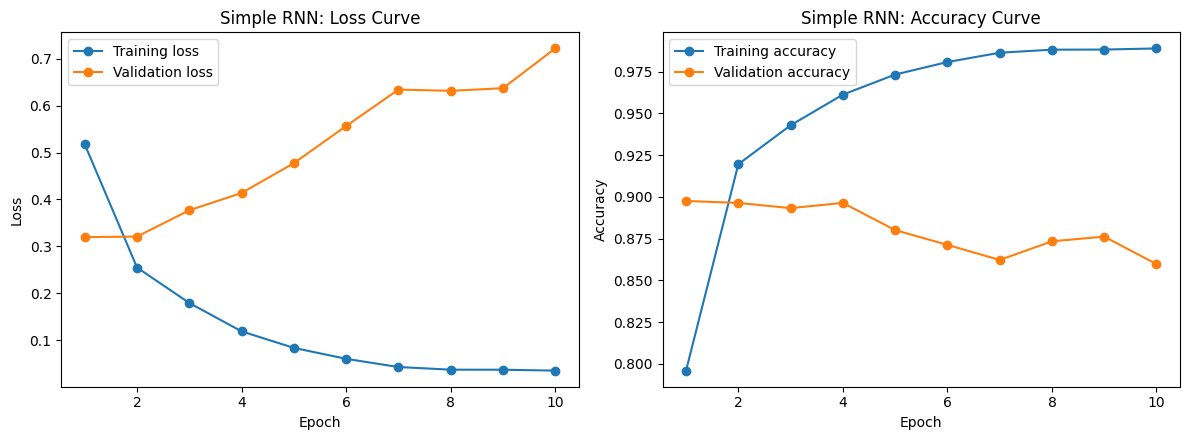

In [30]:
plot_history(history_rnn, "Simple RNN")

## Task 4: Build an LSTM Model

A Long Short-Term Memory (LSTM) network is an improvement on the Simple RNN. In addition to the hidden state, it keeps a separate **cell state**, a long-term memory, and uses three **gates** to control it:

- **Forget gate:** decides what to erase from the long-term memory.
- **Input gate:** decides what new information from the current word to store.
- **Output gate:** decides how much of the memory to expose as the hidden state at this step.

These gates let the network keep important information across many words and reduce the vanishing gradient problem that limits a Simple RNN.

The architecture and all training settings are identical to the Simple RNN model (Embedding 64, recurrent layer with 64 units, Dense 64 with ReLU, softmax output with 4 units, Adam, 10 epochs, batch size 128). **Only the recurrent layer is changed**, so any difference in results comes from the LSTM itself.

### Model Architecture

1. **Embedding layer:** converts each word ID into a learned 64-dimensional vector.
2. **LSTM layer (64 units):** reads the 100 word vectors in order and returns its final hidden state. It has four sets of weights (three gates plus the candidate memory update), so it has about four times as many parameters as the Simple RNN layer.
3. **Dense hidden layer (64 units, ReLU).**
4. **Output layer (4 units, softmax).**

In [31]:
from tensorflow.keras.layers import LSTM

# Build the LSTM model (same helper function, only the recurrent layer changes)
model_lstm = build_model(LSTM(HIDDEN_UNITS))

# Model summary
model_lstm.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,317,444 (5.03 MB)

 Trainable params: 1,317,444 (5.03 MB)

 Non-trainable params: 0 (0.00 B)

### Training the LSTM Model

The model is trained with the same settings as the Simple RNN: 10 epochs, batch size 128, 96,000 training articles and 24,000 validation articles. The training time is recorded for the final comparison.

In [32]:
history_lstm, time_lstm = train_model(model_lstm, "LSTM")

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 9ms/step - accuracy: 0.8319 - loss: 0.4366 - val_accuracy: 0.9140 - val_loss: 0.2655
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9308 - loss: 0.2151 - val_accuracy: 0.9127 - val_loss: 0.2766
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9451 - loss: 0.1696 - val_accuracy: 0.9104 - val_loss: 0.2897
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9538 - loss: 0.1366 - val_accuracy: 0.9093 - val_loss: 0.3094
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9630 - loss: 0.1086 - val_accuracy: 0.9041 - val_loss: 0.3462
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9691 - loss: 0.0876 - val_accuracy: 0.8995 - val_loss: 0.3773
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9746 - loss: 0.0706 - val_accuracy: 0.8899 - val_loss: 0.4146
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9792 - loss: 0.0575 - val_accuracy: 0

### Evaluating the LSTM Model

The trained model is evaluated on the 7,600 test articles. The training and validation accuracy reported are the values from the final epoch.

In [33]:
evaluate_model(model_lstm, history_lstm, time_lstm, "LSTM")

LSTM results
Training accuracy   : 0.9858
Validation accuracy : 0.8994
Test accuracy       : 0.8938
Test loss           : 0.5757
Training time       : 69.5 seconds


### Loss and Accuracy Curves

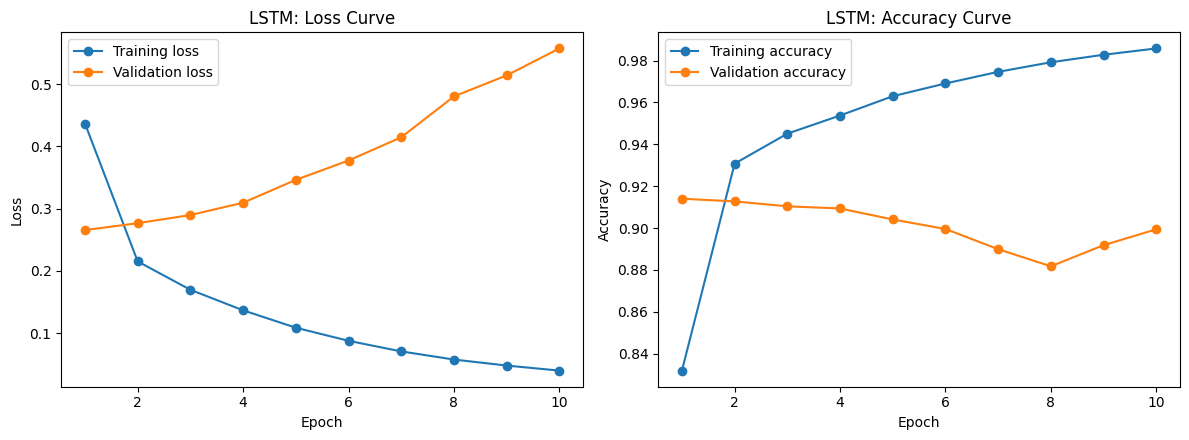

In [34]:
plot_history(history_lstm, "LSTM")

### Comparison with the Simple RNN Model

The two models are compared using the final-epoch results, together with each model's best validation accuracy and the epoch at which it occurred (useful because every model is trained for a fixed 10 epochs without early stopping).

,Train Acc,Val Acc (final),Test Acc,Train-Val Gap,Final Val Loss,Best Val Acc,Best Epoch,Train Time (s)
Model,,,,,,,,
Simple RNN,0.9889,0.8597,0.8601,0.1292,0.7216,0.8975,1,81.0
LSTM,0.9858,0.8994,0.8938,0.0864,0.5573,0.9140,1,69.5


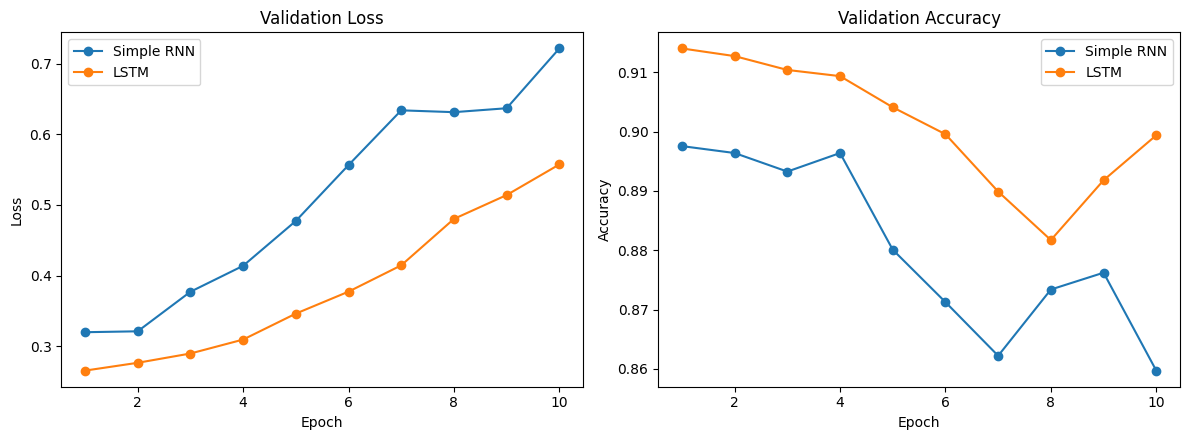

In [35]:
def compare_models(names):
    """Build a comparison table for the given models from the stored results."""
    rows = []
    for n in names:
        r = results[n]
        h = r["history"]
        rows.append({
            "Model": n,
            "Train Acc": round(r["train_acc"], 4),
            "Val Acc (final)": round(r["val_acc"], 4),
            "Test Acc": round(r["test_acc"], 4),
            "Train-Val Gap": round(r["train_acc"] - r["val_acc"], 4),
            "Final Val Loss": round(h["val_loss"][-1], 4),
            "Best Val Acc": round(max(h["val_accuracy"]), 4),
            "Best Epoch": int(np.argmax(h["val_accuracy"])) + 1,
            "Train Time (s)": round(r["train_time_sec"], 1),
        })
    return pd.DataFrame(rows).set_index("Model")


def plot_comparison(names):
    """Overlay the validation curves of several models."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for n in names:
        h = results[n]["history"]
        epochs_range = range(1, len(h["val_loss"]) + 1)
        axes[0].plot(epochs_range, h["val_loss"], marker="o", label=n)
        axes[1].plot(epochs_range, h["val_accuracy"], marker="o", label=n)

    axes[0].set_title("Validation Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].set_title("Validation Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()


# Compare Simple RNN and LSTM
display(compare_models(["Simple RNN", "LSTM"]))
plot_comparison(["Simple RNN", "LSTM"])

## Task 5: Build a GRU Model

A Gated Recurrent Unit (GRU) is a simplified relative of the LSTM. It uses only two gates and has no separate cell state:

- **Reset gate:** decides how much of the previous hidden state to ignore when computing the new candidate memory.
- **Update gate:** decides how much of the old hidden state to keep and how much of the new candidate to use.

Like the LSTM, these gates let the network remember information across many words and reduce the vanishing gradient problem of the Simple RNN. Because the GRU has three sets of weights instead of the LSTM's four, it has fewer parameters and is usually faster to train.

The architecture and all training settings are identical to the previous models (Embedding 64, recurrent layer with 64 units, Dense 64 with ReLU, softmax output with 4 units, Adam, 10 epochs, batch size 128). **Only the recurrent layer is changed.**

### Model Architecture

1. **Embedding layer:** converts each word ID into a learned 64-dimensional vector.
2. **GRU layer (64 units):** reads the 100 word vectors in order and returns its final hidden state.
3. **Dense hidden layer (64 units, ReLU).**
4. **Output layer (4 units, softmax).**

In [36]:
from tensorflow.keras.layers import GRU

# Build the GRU model (same helper function, only the recurrent layer changes)
model_gru = build_model(GRU(HIDDEN_UNITS))

# Model summary
model_gru.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru (GRU)                       │ (None, 64)             │        24,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,309,380 (4.99 MB)

 Trainable params: 1,309,380 (4.99 MB)

 Non-trainable params: 0 (0.00 B)

### Training the GRU Model

The model is trained with the same settings as the previous models: 10 epochs, batch size 128, 96,000 training articles and 24,000 validation articles. The training time is recorded for the final comparison.

In [37]:
history_gru, time_gru = train_model(model_gru, "GRU")

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - accuracy: 0.8285 - loss: 0.4451 - val_accuracy: 0.9065 - val_loss: 0.2830
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9244 - loss: 0.2316 - val_accuracy: 0.9130 - val_loss: 0.2731
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9439 - loss: 0.1753 - val_accuracy: 0.9087 - val_loss: 0.2890
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - accuracy: 0.9563 - loss: 0.1382 - val_accuracy: 0.9042 - val_loss: 0.3275
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 9ms/step - accuracy: 0.9644 - loss: 0.1107 - val_accuracy: 0.9033 - val_loss: 0.3557
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9708 - loss: 0.0898 - val_accuracy: 0.8942 - val_loss: 0.4481
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9758 - loss: 0.0733 - val_accuracy: 0.8892 - val_loss: 0.4723
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - accuracy: 0.9814 - loss: 0.0570 - val_accuracy: 0.

### Evaluating the GRU Model

The trained model is evaluated on the 7,600 test articles. The training and validation accuracy reported are the values from the final epoch.

In [38]:
evaluate_model(model_gru, history_gru, time_gru, "GRU")

GRU results
Training accuracy   : 0.9875
Validation accuracy : 0.8901
Test accuracy       : 0.8889
Test loss           : 0.6271
Training time       : 65.6 seconds


### Loss and Accuracy Curves

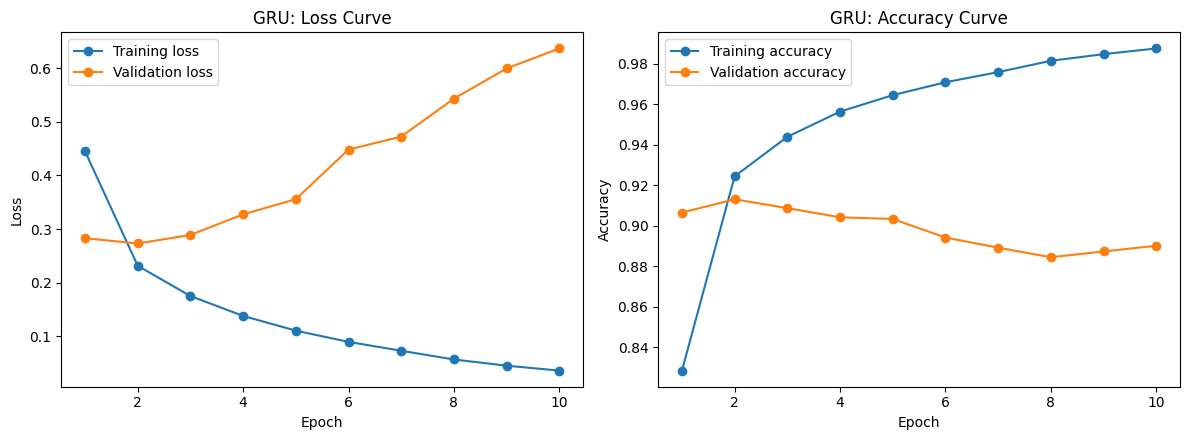

In [39]:
plot_history(history_gru, "GRU")

### Comparison with the Simple RNN and LSTM Models

The three models are compared using the final-epoch results, together with each model's best validation accuracy and the epoch at which it occurred. The validation curves of all three models are also plotted together.

,Train Acc,Val Acc (final),Test Acc,Train-Val Gap,Final Val Loss,Best Val Acc,Best Epoch,Train Time (s)
Model,,,,,,,,
Simple RNN,0.9889,0.8597,0.8601,0.1292,0.7216,0.8975,1,81.0
LSTM,0.9858,0.8994,0.8938,0.0864,0.5573,0.9140,1,69.5
GRU,0.9875,0.8901,0.8889,0.0974,0.6366,0.9130,2,65.6


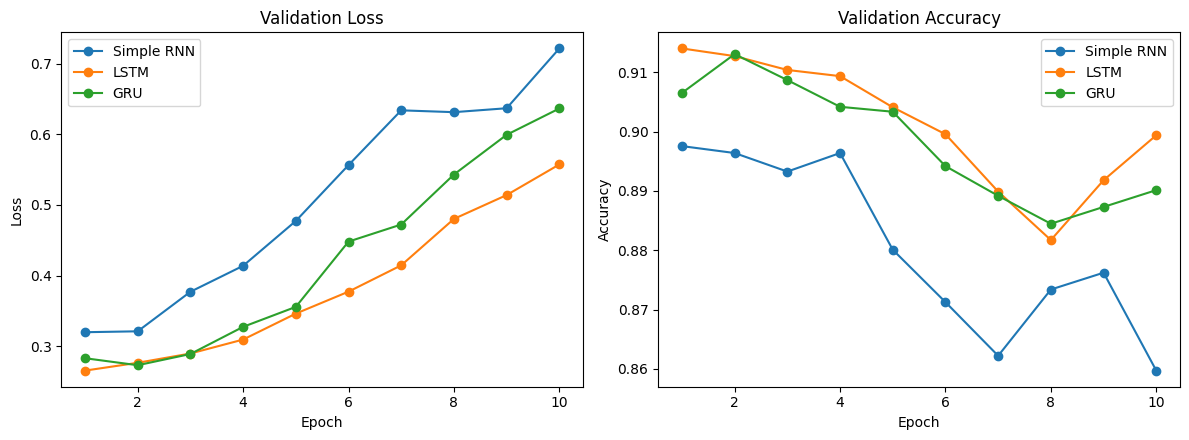

In [40]:
# Comparison table for the three models trained so far
display(compare_models(["Simple RNN", "LSTM", "GRU"]))

# Overlay the validation curves
plot_comparison(["Simple RNN", "LSTM", "GRU"])

## Task 6: Build a Bidirectional LSTM Model

A standard LSTM reads an article from the first word to the last, so at every step it only knows the words that came **before** the current one. A **Bidirectional LSTM (Bi-LSTM)** runs two separate LSTMs over the same article:

- a **forward LSTM**, reading from the first word to the last, and
- a **backward LSTM**, reading from the last word to the first.

The final hidden states of the two LSTMs are **concatenated**, so the classifier receives information from both directions. With 64 units in each direction, the output is a 128-number summary of the article. This lets the model use context from both sides of every word, which can help when the meaning of a word depends on what follows it as well as what precedes it.

All other settings are identical to the previous models (Embedding 64, Dense 64 with ReLU, softmax output with 4 units, Adam, 10 epochs, batch size 128). The recurrent layer is the Bidirectional LSTM, and because it outputs 128 values instead of 64, the following Dense layer receives twice as many inputs.

### Model Architecture

1. **Embedding layer:** converts each word ID into a learned 64-dimensional vector.
2. **Bidirectional LSTM layer (64 units per direction):** a forward and a backward LSTM read the 100 word vectors, and their outputs are concatenated into a 128-dimensional vector. It has twice as many parameters as a single LSTM.
3. **Dense hidden layer (64 units, ReLU).**
4. **Output layer (4 units, softmax).**

In [41]:
from tensorflow.keras.layers import Bidirectional, LSTM

# Build the Bi-LSTM model (same helper function, recurrent layer wrapped in Bidirectional)
model_bilstm = build_model(Bidirectional(LSTM(HIDDEN_UNITS)))

# Model summary
model_bilstm.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ (None, 100, 64)        │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ (None, 128)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,354,564 (5.17 MB)

 Trainable params: 1,354,564 (5.17 MB)

 Non-trainable params: 0 (0.00 B)

### Training the Bi-LSTM Model

The model is trained with the same settings as the previous models: 10 epochs, batch size 128, 96,000 training articles and 24,000 validation articles. The training time is recorded for the final comparison.

In [42]:
history_bilstm, time_bilstm = train_model(model_bilstm, "Bi-LSTM")

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 13ms/step - accuracy: 0.8445 - loss: 0.4144 - val_accuracy: 0.9159 - val_loss: 0.2549
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9329 - loss: 0.2078 - val_accuracy: 0.9148 - val_loss: 0.2607
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9475 - loss: 0.1630 - val_accuracy: 0.9075 - val_loss: 0.2958
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9549 - loss: 0.1348 - val_accuracy: 0.9093 - val_loss: 0.2966
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9628 - loss: 0.1098 - val_accuracy: 0.9054 - val_loss: 0.3419
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 13ms/step - accuracy: 0.9693 - loss: 0.0896 - val_accuracy: 0.9013 - val_loss: 0.3791
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9750 - loss: 0.0732 - val_accuracy: 0.8917 - val_loss: 0.4310
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 12ms/step - accuracy: 0.9814 - loss: 0.0547 - val_acc

### Evaluating the Bi-LSTM Model

The trained model is evaluated on the 7,600 test articles. The training and validation accuracy reported are the values from the final epoch.



In [43]:
evaluate_model(model_bilstm, history_bilstm, time_bilstm, "Bi-LSTM")

Bi-LSTM results
Training accuracy   : 0.9855
Validation accuracy : 0.8887
Test accuracy       : 0.8887
Test loss           : 0.4906
Training time       : 95.8 seconds


### Loss and Accuracy Curves

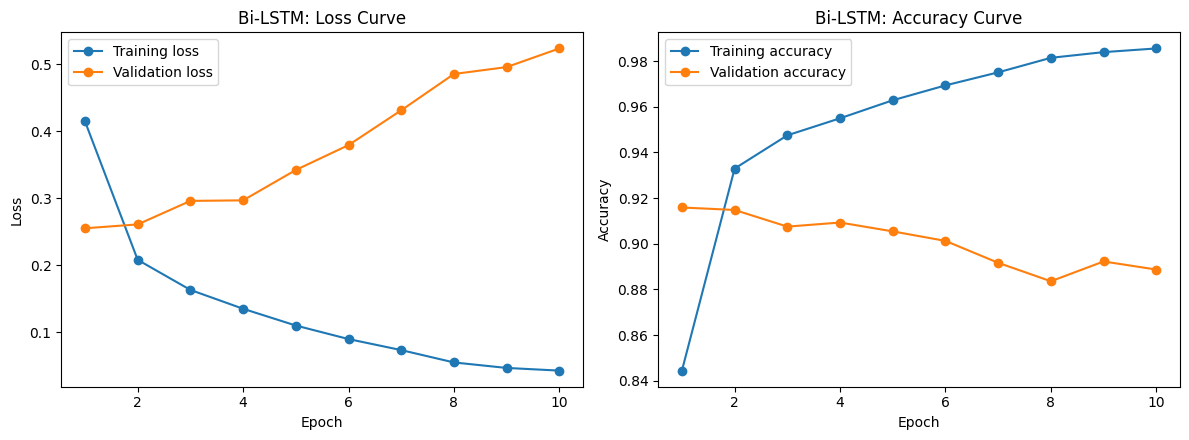

In [44]:
plot_history(history_bilstm, "Bi-LSTM")

### Comparison with the Regular LSTM

The Bi-LSTM is compared with the regular LSTM using the final-epoch results, together with each model's best validation accuracy and the epoch at which it occurred. The validation curves of both models are also plotted together.

,Train Acc,Val Acc (final),Test Acc,Train-Val Gap,Final Val Loss,Best Val Acc,Best Epoch,Train Time (s)
Model,,,,,,,,
LSTM,0.9858,0.8994,0.8938,0.0864,0.5573,0.9140,1,69.5
Bi-LSTM,0.9855,0.8887,0.8887,0.0968,0.5233,0.9159,1,95.8


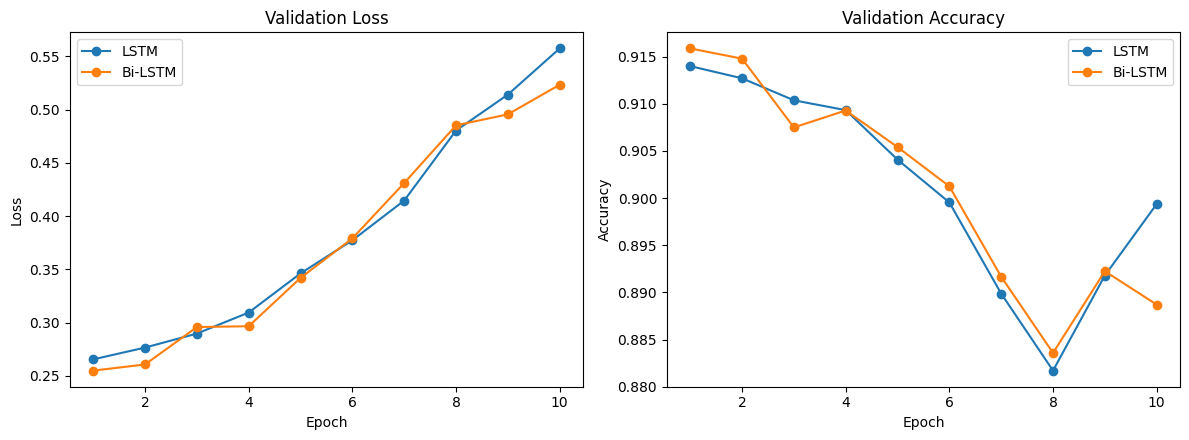

In [45]:
# Compare the regular LSTM and the Bi-LSTM
display(compare_models(["LSTM", "Bi-LSTM"]))
plot_comparison(["LSTM", "Bi-LSTM"])

## Task 7: Apply Gradient Clipping

### Background

During backpropagation through time, the gradient is multiplied by the recurrent weights at every word step. Over a sequence of 100 words, this repeated multiplication can make gradients grow very large, which is called the **exploding gradient problem**. A single oversized gradient can produce a huge weight update, causing the loss to spike or even become `NaN`.

**Gradient clipping** protects against this by capping the size of the gradient before each weight update. In this task `global_clipnorm = 1.0` is used: if the overall gradient norm exceeds 1.0, all gradients are rescaled so that the norm equals 1.0. The *direction* of the update is preserved, and only its *size* is limited. Gradients smaller than the threshold are left unchanged.

### Experiment Design

- **Selected model:** Simple RNN. It is the model most prone to exploding gradients because it has no gating mechanism, and it is the fastest to retrain.
- **Run 1:** Simple RNN trained with the standard Adam optimizer (no clipping).
- **Run 2:** The same model trained with `Adam(global_clipnorm=1.0)`.
- Everything else is identical (same architecture, data, epochs, batch size and random seed), so any difference in behaviour is due to clipping alone.
- In addition to the training curves, the **raw (unclipped) gradient norm** is recorded on a fixed sample of 2,048 training articles before training and after every epoch. This shows whether gradients were ever large enough for clipping to matter.

In [46]:
# Names under which the two runs are stored (Task 3 results are NOT overwritten)
NAME_NOCLIP = "Simple RNN (no clipping)"
NAME_CLIP = "Simple RNN (clipped)"
CLIP_NORM = 1.0

grad_norms = {}   # raw gradient norms recorded during each run


class GradNormLogger(tf.keras.callbacks.Callback):
    """Records the raw (unclipped) global gradient norm on a fixed sample batch,
    once before training and again at the end of every epoch."""

    def __init__(self, x, y):
        super().__init__()
        self.x = tf.convert_to_tensor(x)
        self.y = tf.convert_to_tensor(y)
        self.loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()
        self.norms = []

    def _measure(self):
        with tf.GradientTape() as tape:
            preds = self.model(self.x, training=False)
            loss = self.loss_fn(self.y, preds)
        grads = tape.gradient(loss, self.model.trainable_weights)
        grads = [g for g in grads if g is not None]
        self.norms.append(float(tf.linalg.global_norm(grads)))

    def on_train_begin(self, logs=None):
        self._measure()

    def on_epoch_end(self, epoch, logs=None):
        self._measure()


def train_with_gradnorm(model, name):
    """Same as train_model, but also records the raw gradient norms."""
    logger = GradNormLogger(X_tr[:2048], y_tr[:2048])
    start = time.time()
    history = model.fit(
        X_tr, y_tr,
        validation_data=(X_val, y_val),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        verbose=1,
        callbacks=[logger],
    )
    train_time = time.time() - start
    grad_norms[name] = logger.norms
    print(f"\n{name} training time: {train_time:.1f} seconds ({train_time / 60:.1f} minutes)")
    return history, train_time

### Run 1: Simple RNN Trained Without Gradient Clipping

The Simple RNN is trained with the standard Adam optimizer, exactly as in Task 3.

In [47]:
model_noclip = build_model(SimpleRNN(HIDDEN_UNITS))
history_noclip, time_noclip = train_with_gradnorm(model_noclip, NAME_NOCLIP)
evaluate_model(model_noclip, history_noclip, time_noclip, NAME_NOCLIP)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.8049 - loss: 0.4918 - val_accuracy: 0.8915 - val_loss: 0.3270
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9255 - loss: 0.2361 - val_accuracy: 0.8971 - val_loss: 0.3347
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9455 - loss: 0.1737 - val_accuracy: 0.8991 - val_loss: 0.3589
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9603 - loss: 0.1260 - val_accuracy: 0.8867 - val_loss: 0.4889
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9683 - loss: 0.0990 - val_accuracy: 0.8800 - val_loss: 0.4922
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9787 - loss: 0.0674 - val_accuracy: 0.8734 - val_loss: 0.5381
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9846 - loss: 0.0486 - val_accuracy: 0.8733 - val_loss: 0.6187
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9877 - loss: 0.0385 - val_acc

### Run 2: Simple RNN Trained With Gradient Clipping

The same model is trained again, using Adam with `global_clipnorm=1.0`. Because the random seed is reset inside `build_model`, this model starts from the same initial weights as Run 1.

In [48]:
optimizer_clip = tf.keras.optimizers.Adam(global_clipnorm=CLIP_NORM)
model_clip = build_model(SimpleRNN(HIDDEN_UNITS), optimizer=optimizer_clip)
history_clip, time_clip = train_with_gradnorm(model_clip, NAME_CLIP)
evaluate_model(model_clip, history_clip, time_clip, NAME_CLIP)

Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.7049 - loss: 0.6851 - val_accuracy: 0.8716 - val_loss: 0.4005
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9013 - loss: 0.3108 - val_accuracy: 0.8967 - val_loss: 0.3390
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9308 - loss: 0.2247 - val_accuracy: 0.8940 - val_loss: 0.3441
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9481 - loss: 0.1665 - val_accuracy: 0.8840 - val_loss: 0.4457
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9623 - loss: 0.1211 - val_accuracy: 0.8869 - val_loss: 0.4760
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9699 - loss: 0.0966 - val_accuracy: 0.8662 - val_loss: 0.5498
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9760 - loss: 0.0762 - val_accuracy: 0.8744 - val_loss: 0.5712
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 8s 11ms/step - accuracy: 0.9786 - loss: 0.0688 - val_acc

### Training Loss Curve: Before and After Gradient Clipping

Both plots use the same y-axis scale so they can be compared directly.

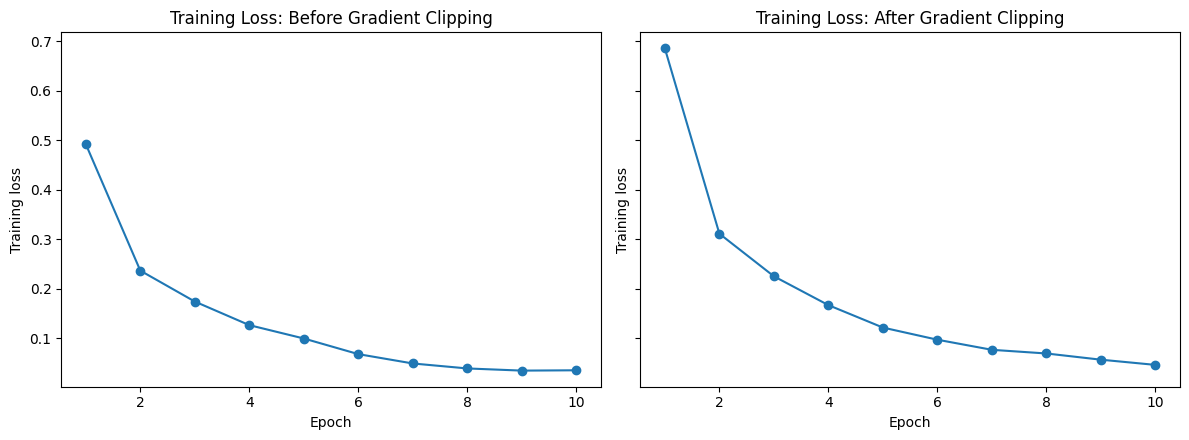

In [49]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
epochs_range = range(1, EPOCHS + 1)

panels = [(NAME_NOCLIP, "Before Gradient Clipping"), (NAME_CLIP, "After Gradient Clipping")]
for ax, (name, title) in zip(axes, panels):
    ax.plot(epochs_range, results[name]["history"]["loss"], marker="o")
    ax.set_title(f"Training Loss: {title}")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Training loss")

plt.tight_layout()
plt.show()

### Direct Comparison of the Two Runs

The training and validation losses of both runs are overlaid to make any difference in speed or stability easier to see.

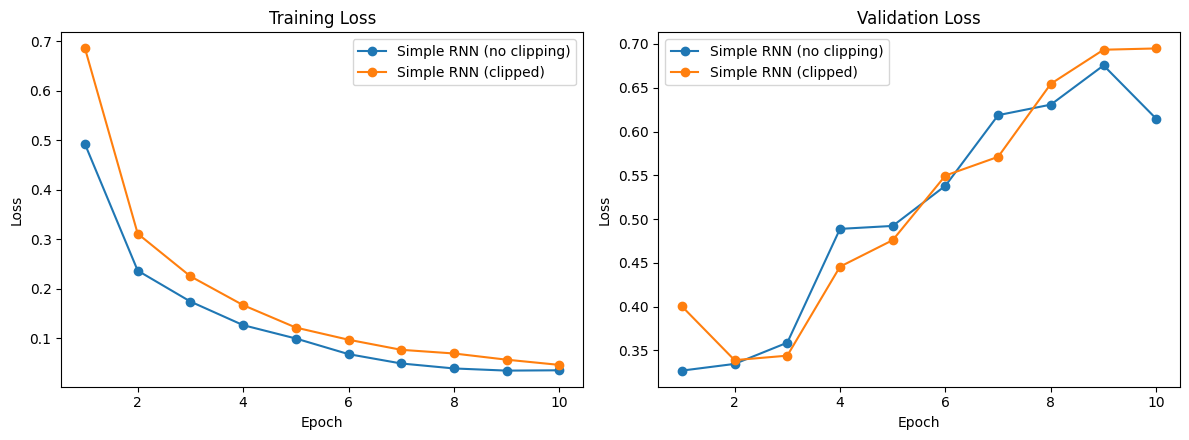

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name in [NAME_NOCLIP, NAME_CLIP]:
    h = results[name]["history"]
    axes[0].plot(epochs_range, h["loss"], marker="o", label=name)
    axes[1].plot(epochs_range, h["val_loss"], marker="o", label=name)

axes[0].set_title("Training Loss")
axes[1].set_title("Validation Loss")
for ax in axes:
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.legend()

plt.tight_layout()
plt.show()

### Raw Gradient Norm During Training

This plot shows the size (global norm) of the raw, unclipped gradient measured on a fixed sample of 2,048 training articles, before training (epoch 0) and after each epoch. The red dashed line is the clipping threshold: gradients above it would be scaled down by the clipped optimizer. Note that this is measured on a sample batch, so it indicates the general scale of the gradients rather than the exact size of every individual mini-batch gradient.

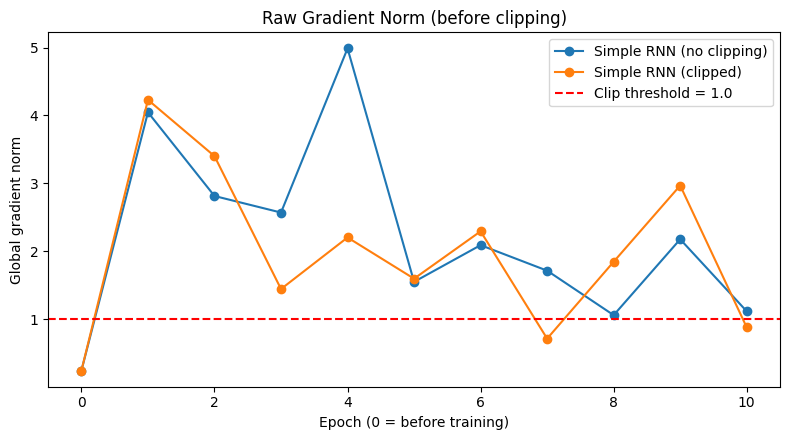

Simple RNN (no clipping) -> [0.241, 4.046, 2.813, 2.569, 4.987, 1.549, 2.089, 1.713, 1.058, 2.176, 1.115]
Simple RNN (clipped) -> [0.241, 4.23, 3.401, 1.443, 2.202, 1.595, 2.293, 0.712, 1.845, 2.968, 0.878]


In [51]:
plt.figure(figsize=(8, 4.5))
for name in [NAME_NOCLIP, NAME_CLIP]:
    plt.plot(range(len(grad_norms[name])), grad_norms[name], marker="o", label=name)
plt.axhline(CLIP_NORM, color="red", linestyle="--", label=f"Clip threshold = {CLIP_NORM}")
plt.title("Raw Gradient Norm (before clipping)")
plt.xlabel("Epoch (0 = before training)")
plt.ylabel("Global gradient norm")
plt.legend()
plt.tight_layout()
plt.show()

for name in [NAME_NOCLIP, NAME_CLIP]:
    print(name, "->", [round(g, 3) for g in grad_norms[name]])

### Stability Comparison

Stability is summarized with a few simple measures: whether the loss ever became `NaN`, how many epochs the training loss went *up* instead of down, and how much the validation loss and accuracy jumped from one epoch to the next (smaller changes mean smoother training).

In [52]:
def stability_stats(name):
    h = results[name]["history"]
    train_loss = np.array(h["loss"])
    val_loss = np.array(h["val_loss"])
    val_acc = np.array(h["val_accuracy"])
    return {
        "Model": name,
        "NaN in loss": bool(np.isnan(train_loss).any()),
        "Final train loss": round(train_loss[-1], 4),
        "Epochs where train loss rose": int((np.diff(train_loss) > 0).sum()),
        "Mean |change| in val loss": round(np.abs(np.diff(val_loss)).mean(), 4),
        "Mean |change| in val acc": round(np.abs(np.diff(val_acc)).mean(), 4),
        "Max raw grad norm": round(max(grad_norms[name]), 3),
    }

stability = pd.DataFrame([stability_stats(NAME_NOCLIP), stability_stats(NAME_CLIP)]).set_index("Model")
display(stability)

# Accuracy, gap and timing for both runs
display(compare_models([NAME_NOCLIP, NAME_CLIP]))

,NaN in loss,Final train loss,Epochs where train loss rose,Mean |change| in val loss,Mean |change| in val acc,Max raw grad norm
Model,,,,,,
Simple RNN (no clipping),False,0.0348,1,0.0455,0.0055,4.987
Simple RNN (clipped),False,0.0457,0,0.0464,0.0102,4.230


,Train Acc,Val Acc (final),Test Acc,Train-Val Gap,Final Val Loss,Best Val Acc,Best Epoch,Train Time (s)
Model,,,,,,,,
Simple RNN (no clipping),0.9892,0.8777,0.8774,0.1114,0.6146,0.8991,3,84.8
Simple RNN (clipped),0.9861,0.8669,0.8683,0.1192,0.6949,0.8967,2,84.9


## Task 8: Compare All RNN-Based Models

The four models (Simple RNN, LSTM, GRU and Bi-LSTM) were trained with identical data, architecture settings, optimizer, number of epochs and batch size, so they can be compared directly. The table below collects the key results of each model:

- **Training accuracy** and **validation accuracy** are the values from the **final epoch** (epoch 10).
- **Test accuracy** is measured on the 7,600 held-out test articles, which were never used during training or validation.
- **Training time** is the total time taken to train for 10 epochs on the same GPU runtime.

In [56]:
model_order = ["Simple RNN", "LSTM", "GRU", "Bi-LSTM"]

# Key observations: to be completed after reviewing the results
key_observations = {
    "Simple RNN": "Fast to train and learns quickly, but overfits clearly and has noisy validation curves",
    "LSTM": "TO BE WRITTEN AFTER RESULTS",
    "GRU": "TO BE WRITTEN AFTER RESULTS",
    "Bi-LSTM": "TO BE WRITTEN AFTER RESULTS",
}

rows = []
for name in model_order:
    r = results[name]
    rows.append({
        "Model": name,
        "Training Accuracy": f"{r['train_acc'] * 100:.2f}%",
        "Validation Accuracy": f"{r['val_acc'] * 100:.2f}%",
        "Test Accuracy": f"{r['test_acc'] * 100:.2f}%",
        "Training Time": f"{r['train_time_sec']:.1f} s ({r['train_time_sec'] / 60:.1f} min)",
        "Key Observation": key_observations[name],
    })

comparison_table = pd.DataFrame(rows).set_index("Model")
display(comparison_table.style.set_properties(**{"text-align": "left", "white-space": "normal"}))

,Training Accuracy,Validation Accuracy,Test Accuracy,Training Time,Key Observation
Model,,,,,
Simple RNN,98.89%,85.97%,86.01%,81.0 s (1.3 min),"Fast to train and learns quickly, but overfits clearly and has noisy validation curves"
LSTM,98.58%,89.94%,89.38%,69.5 s (1.2 min),TO BE WRITTEN AFTER RESULTS
GRU,98.75%,89.01%,88.89%,65.6 s (1.1 min),TO BE WRITTEN AFTER RESULTS
Bi-LSTM,98.55%,88.87%,88.87%,95.8 s (1.6 min),TO BE WRITTEN AFTER RESULTS


### Supporting Metrics

The table below adds the gap between training and validation accuracy (a measure of overfitting), the final validation loss, and each model's **best** validation accuracy together with the epoch at which it occurred. The charts compare test accuracy and training time.

,Train Acc,Val Acc (final),Test Acc,Train-Val Gap,Final Val Loss,Best Val Acc,Best Epoch,Train Time (s)
Model,,,,,,,,
Simple RNN,0.9889,0.8597,0.8601,0.1292,0.7216,0.8975,1,81.0
LSTM,0.9858,0.8994,0.8938,0.0864,0.5573,0.9140,1,69.5
GRU,0.9875,0.8901,0.8889,0.0974,0.6366,0.9130,2,65.6
Bi-LSTM,0.9855,0.8887,0.8887,0.0968,0.5233,0.9159,1,95.8


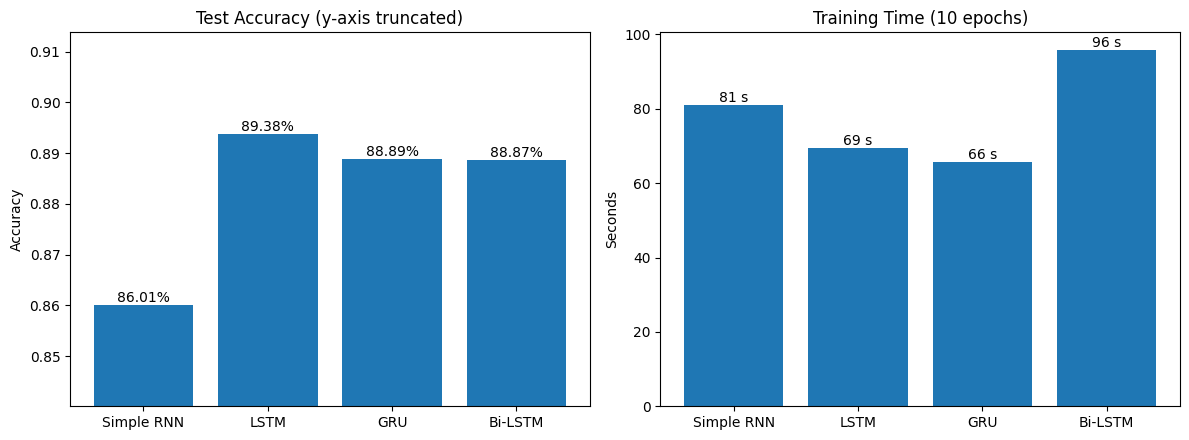

In [54]:
# Supporting metrics for all four models
display(compare_models(model_order))

# Bar charts: test accuracy and training time
test_acc = [results[n]["test_acc"] for n in model_order]
train_time = [results[n]["train_time_sec"] for n in model_order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].bar(model_order, test_acc)
axes[0].set_ylim(min(test_acc) - 0.02, max(test_acc) + 0.02)
axes[0].set_title("Test Accuracy (y-axis truncated)")
axes[0].set_ylabel("Accuracy")
for i, v in enumerate(test_acc):
    axes[0].text(i, v, f"{v * 100:.2f}%", ha="center", va="bottom")

axes[1].bar(model_order, train_time)
axes[1].set_title("Training Time (10 epochs)")
axes[1].set_ylabel("Seconds")
for i, v in enumerate(train_time):
    axes[1].text(i, v, f"{v:.0f} s", ha="center", va="bottom")

plt.tight_layout()
plt.show()

### Validation Curves of All Four Models

The validation loss and validation accuracy of all four models are plotted together to compare how quickly each model learns and how it behaves in later epochs.

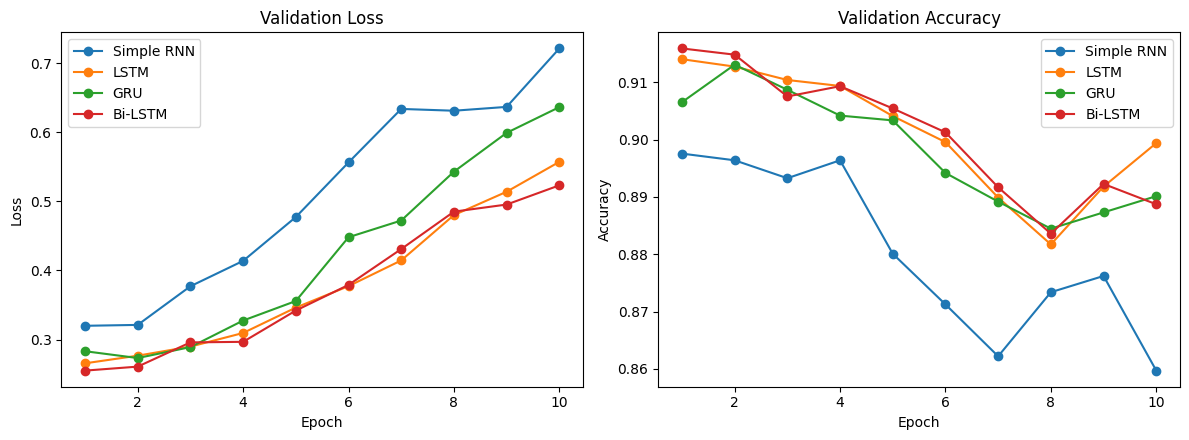

In [55]:
plot_comparison(model_order)